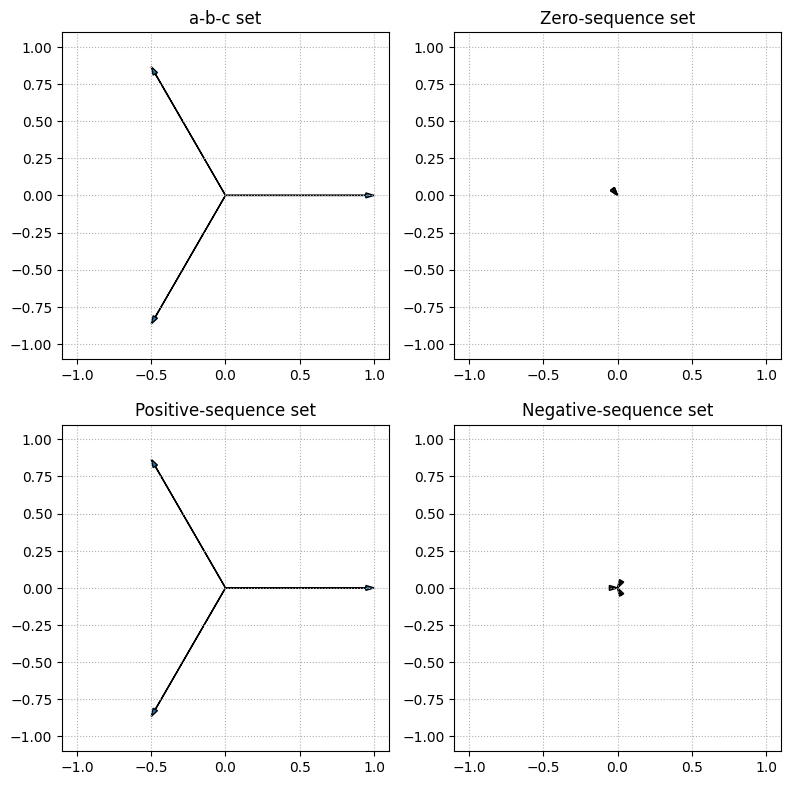

Symmetrical components (rectangular input): [1.11022302e-16-1.37766863e-16j 9.99999998e-01+2.77555756e-16j
 2.18494665e-09-1.39788893e-16j]
Symmetrical components (polar input): [-0.00376351+0.02846341j  0.99746313+0.05810383j  0.00630037-0.08656724j]


In [10]:
# powersystems.py
# Three-phase tools wrapped in a PowerSystems class.
# Comments are in English (as requested).

from typing import Iterable, Tuple
import numpy as np
import matplotlib.pyplot as plt


class PowerSystems:
    """
    Utilities for three-phase phasor calculations.
    """

    def __init__(self):
        # Operator a = e^(j*120°)
        self.a = np.cos(2.0 * np.pi / 3.0) + 1j * np.sin(2.0 * np.pi / 3.0)

        # Phase->sequence transformation matrix:
        # [f0, f1, f2]^T = A^{-1} [fa, fb, fc]^T
        self.A = np.array(
            [
                [1.0, 1.0, 1.0],
                [1.0, self.a**2, self.a],
                [1.0, self.a, self.a**2],
            ],
            dtype=complex,
        )

    # ---------------------------
    # Public methods
    # ---------------------------

    def abc2sc(self, fabc: Iterable, do_plot: bool = True) -> np.ndarray:
        """
        Transform a three-phase unbalanced phasor set (a-b-c) into its
        symmetrical components (0-1-2), returned in rectangular form.

        Parameters
        ----------
        fabc : array-like
            Rectangular: shape (3,) complex numbers [Va, Vb, Vc].
            Polar:       shape (3, 2) with columns [magnitude, angle_deg].
        do_plot : bool
            If True, plots original set and each sequence set (2x2 layout).

        Returns
        -------
        np.ndarray
            Complex array of shape (3,) = [f0, f1, f2].
        """
        fabc_rect = self._as_rectangular(fabc)

        # Solve for symmetrical components: fa012 = A^{-1} * fabc_rect
        fa012 = np.linalg.solve(self.A, fabc_rect)

        if do_plot:
            self._plot_sequences(fabc_rect, fa012)

        return fa012

    # Alias with uppercase name, as requested ("use the function ABC2SC")
    def ABC2SC(self, fabc: Iterable, do_plot: bool = True) -> np.ndarray:
        """
        Uppercase alias for abc2sc to match requested name.
        """
        result = self.abc2sc(fabc, do_plot=do_plot)
        return result

    # ---------------------------
    # Helpers (private)
    # ---------------------------

    def _as_rectangular(self, fabc: Iterable) -> np.ndarray:
        """
        Normalize input to rectangular complex array of shape (3,).
        Accepts:
          - (3,) complex
          - (3,2) polar: [magnitude, angle_deg]
        """
        arr = np.asarray(fabc)
        if arr.ndim == 2 and arr.shape == (3, 2):
            mag = arr[:, 0]
            ang_deg = arr[:, 1]
            ang_rad = np.pi * ang_deg / 180.0
            fabc_rect = mag * (np.cos(ang_rad) + 1j * np.sin(ang_rad))
        elif arr.ndim == 1 and arr.shape[0] == 3:
            fabc_rect = arr.astype(complex)
        else:
            raise ValueError(
                "Input must be (3,) complex (rectangular) or (3,2) [magnitude, angle_deg] (polar)."
            )
        return fabc_rect

    def _plot_sequences(self, fabc_rect: np.ndarray, fa012: np.ndarray) -> None:
        """
        Plot original a-b-c set and zero/positive/negative sequence sets.
        """
        fabc0 = fa012[0] * np.array([1.0, 1.0, 1.0], dtype=complex)
        fabc1 = fa012[1] * np.array([1.0, self.a**2, self.a], dtype=complex)
        fabc2 = fa012[2] * np.array([1.0, self.a, self.a**2], dtype=complex)

        vmax = np.max(
            [
                np.max(np.abs(fabc_rect)),
                np.max(np.abs(fabc0)),
                np.max(np.abs(fabc1)),
                np.max(np.abs(fabc2)),
            ]
        )
        vscale = 1.10 * vmax if vmax > 0.0 else 1.0

        fig, axs = plt.subplots(2, 2, figsize=(8, 8))
        self._plot_phasors(axs[0, 0], fabc_rect, "a-b-c set", vscale)
        self._plot_phasors(axs[0, 1], fabc0, "Zero-sequence set", vscale)
        self._plot_phasors(axs[1, 0], fabc1, "Positive-sequence set", vscale)
        self._plot_phasors(axs[1, 1], fabc2, "Negative-sequence set", vscale)
        plt.tight_layout()
        plt.show()

    def _plot_phasors(self, ax, phasors: np.ndarray, title: str, vscale: float) -> None:
        """
        Draw three phasors as arrows from origin with equal axes.
        """
        ph = np.asarray(phasors, dtype=complex)
        x_vals = np.real(ph)
        y_vals = np.imag(ph)

        # ax.axhline(0.0, linewidth=1.0)
        # ax.axvline(0.0, linewidth=1.0)

        # Draw each phasor as arrow
        for k in range(3):
            ax.arrow(
                0.0,
                0.0,
                x_vals[k],
                y_vals[k],
                length_includes_head=True,
                head_width=0.03 * vscale,
                head_length=0.05 * vscale,
            )

        # Connect tips (optional visual aid)
        # ax.plot(x_vals, y_vals, marker="o", linestyle="-")

        ax.set_title(title)
        ax.set_xlim(-vscale, vscale)
        ax.set_ylim(-vscale, vscale)
        ax.set_aspect("equal", adjustable="box")
        ax.grid(True, ls="dotted")


# ---------------------------
# Example of how to use ABC2SC
# ---------------------------
if __name__ == "__main__":
    ps = PowerSystems()

    # Example 1: rectangular input (balanced positive sequence)
    fabc_rect = np.array([1.0 + 0.0j, -0.5  -0.8660254j, -0.5 + 0.8660254j])
    sc_rect = ps.ABC2SC(fabc_rect, do_plot=True)
    print("Symmetrical components (rectangular input):", sc_rect)

    # Example 2: polar input ([magnitude, angle_deg])
    fabc_polar = np.array([[1.0, 0.0], [0.9, -115.0], [1.1, 125.0]])
    sc_pol = ps.ABC2SC(fabc_polar, do_plot=False)
    print("Symmetrical components (polar input):", sc_pol)
